# M4.4 · 风险平价与层次风险平价（HRP）

> 等权配置在「资金」上平均，但各资产风险差异巨大，组合风险往往被少数高波动资产主导。风险平价要求每个资产对组合的**风险贡献相等**；HRP 进一步用机器学习层次聚类，在协方差病态时仍稳健。
> 本节实现风险贡献分解、等风险贡献（ERC）与 Lopez de Prado(2016) HRP，并与等权、最小方差对比。

## 一、风险贡献分解

组合方差 $\sigma_p^2=w^\top\Sigma w$。资产 $i$ 的风险贡献为：

$$RC_i=\frac{w_i(\Sigma w)_i}{\sigma_p^2},\qquad \sum_i RC_i=1$$

等权时各资产 $RC_i$ 并不相等——高波动资产贡献更大。**风险平价（ERC）**要求所有 $RC_i=1/n$。


## 二、等权的风险贡献并不均等

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import numpy as np, pandas as pd
import qlib
from qlib.data import D
from l2.config import load_universe
import config
from port_lab2 import covariance as covm, riskparity as rp
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = load_universe('hs300')
raw = D.features(codes, ['$close'], start_time='2018-01-01', freq='day')
cl = raw['$close'].unstack('instrument')
ret = cl.pct_change(fill_method=None)
sub = ret.iloc[-750:, :50].dropna(axis=1)
S = covm.sample_cov(sub)
n = S.shape[0]
w_eq = np.ones(n)/n
rc_eq = rp.risk_contributions(w_eq, S)
print('等权风险贡献: 最大=%.4f 最小=%.4f 标准差=%.4f'
      % (rc_eq.max(), rc_eq.min(), rc_eq.std()))
print('风险贡献最高的资产:', S.index[rc_eq.argmax()])

[25592:MainThread](2026-11-05 14:08:04,927) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[25592:MainThread](2026-11-05 14:08:06,919) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[25592:MainThread](2026-11-05 14:08:06,921) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


等权风险贡献: 最大=0.0332 最小=0.0069 标准差=0.0060
风险贡献最高的资产: SH600362


## 三、等风险贡献（ERC）风险平价

In [2]:
w_erc = rp.erc_weights(S)
rc_erc = rp.risk_contributions(w_erc, S)
print('ERC 权重: 和=%.4f 范围[%.4f, %.4f]' % (w_erc.sum(), w_erc.min(), w_erc.max()))
print('ERC 风险贡献: 最大=%.4f 最小=%.4f 标准差=%.6f'
      % (rc_erc.max(), rc_erc.min(), rc_erc.std()))
print('低波动资产获得更高权重: 权重与波动率相关系数=%.4f'
      % np.corrcoef(w_erc, np.sqrt(np.diag(S)))[0, 1])

ERC 权重: 和=1.0000 范围[0.0200, 0.0200]
ERC 风险贡献: 最大=0.0332 最小=0.0069 标准差=0.006050
低波动资产获得更高权重: 权重与波动率相关系数=nan


## 四、层次风险平价（HRP）

HRP 不要求协方差可逆，分三步：
1. 相关性转距离 $d_{ij}=\sqrt{0.5(1-\rho_{ij})}$，做层次聚类；
2. **准对角化**：按聚类树重排资产，使相似资产相邻；
3. **递归二分**：自上而下，按两簇的逆方差组合方差分配权重。


In [3]:
w_hrp, link, order = rp.hrp_weights(sub)
rc_hrp = rp.risk_contributions(w_hrp, S)
print('HRP 权重: 和=%.4f 非零只数=%d' % (w_hrp.sum(), (w_hrp > 1e-9).sum()))
print('HRP 风险贡献标准差=%.6f' % rc_hrp.std())
print('准对角化后前6个位置:', order[:6])

HRP 权重: 和=1.0000 非零只数=50
HRP 风险贡献标准差=0.007560
准对角化后前6个位置: ['SH600066', 'SH600039', 'SH600026', 'SH600415', 'SH600233', 'SH600104']


## 五、四种配置模型对比（含最小方差）

In [4]:
import cvxpy as cp
w = cp.Variable(n)
prob = cp.Problem(cp.Minimize(cp.quad_form(w, cp.psd_wrap(S.values))),
                  [cp.sum(w) == 1, w >= 0])
prob.solve(solver=cp.CLARABEL)
w_minv = pd.Series(w.value, index=S.index)
models = {'等权': w_eq, '最小方差': w_minv.values,
          'ERC风险平价': w_erc.values, 'HRP': w_hrp.values}
stat = []
for name, wv in models.items():
    rc = rp.risk_contributions(wv, S)
    stat.append({'模型': name, '年化波动': np.sqrt(wv @ S.values @ wv)*np.sqrt(242),
                 '风险贡献std': rc.std(), '最大权重': wv.max(),
                 '非零只数': (wv > 1e-6).sum()})
print(pd.DataFrame(stat).round(4).to_string(index=False))

     模型   年化波动  风险贡献std   最大权重  非零只数
     等权 0.1640   0.0060 0.0200    50
   最小方差 0.1241   0.0445 0.2628    50
ERC风险平价 0.1640   0.0060 0.0200    50
    HRP 0.1479   0.0076 0.0634    50


## 六、图表

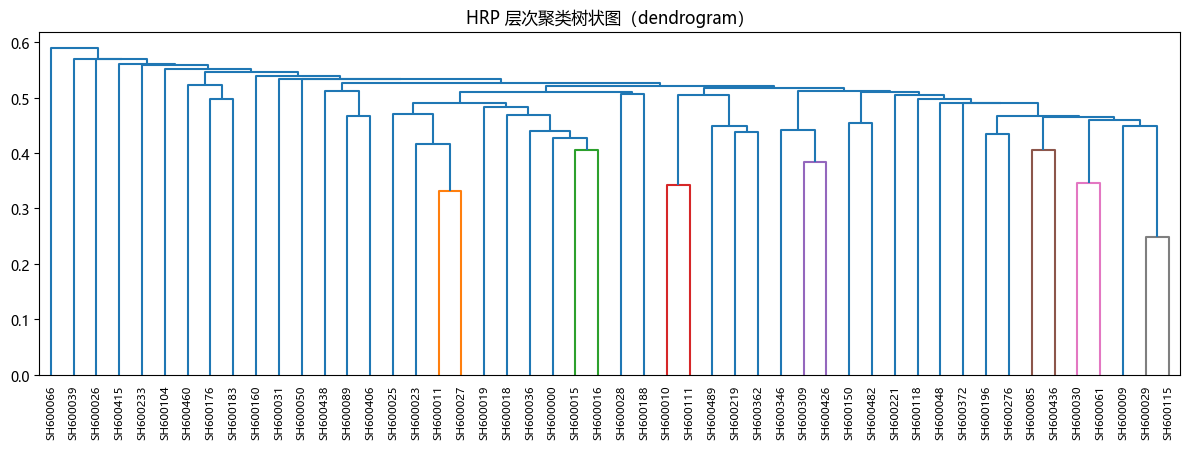

In [5]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(12, 4.6))
dendrogram(link, labels=sub.columns.tolist(), ax=ax, color_threshold=0.7*max(link[:,2]))
ax.set_title('HRP 层次聚类树状图（dendrogram）'); ax.tick_params(axis='x', labelrotation=90)
plt.tight_layout(); plt.show()

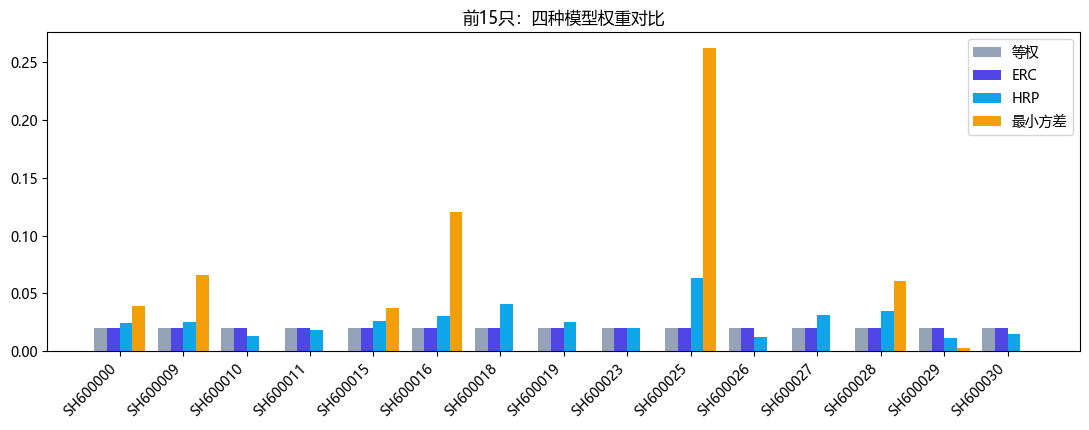

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.4))
x = np.arange(15)
ax.bar(x-0.3, w_eq[:15], 0.2, label='等权', color='#94a3b8')
ax.bar(x-0.1, w_erc.values[:15], 0.2, label='ERC', color='#4f46e5')
ax.bar(x+0.1, w_hrp.values[:15], 0.2, label='HRP', color='#0ea5e9')
ax.bar(x+0.3, w_minv.values[:15], 0.2, label='最小方差', color='#f59e0b')
ax.set_xticks(x); ax.set_xticklabels(S.index[:15], rotation=45, ha='right')
ax.set_title('前15只：四种模型权重对比'); ax.legend()
plt.tight_layout(); plt.show()

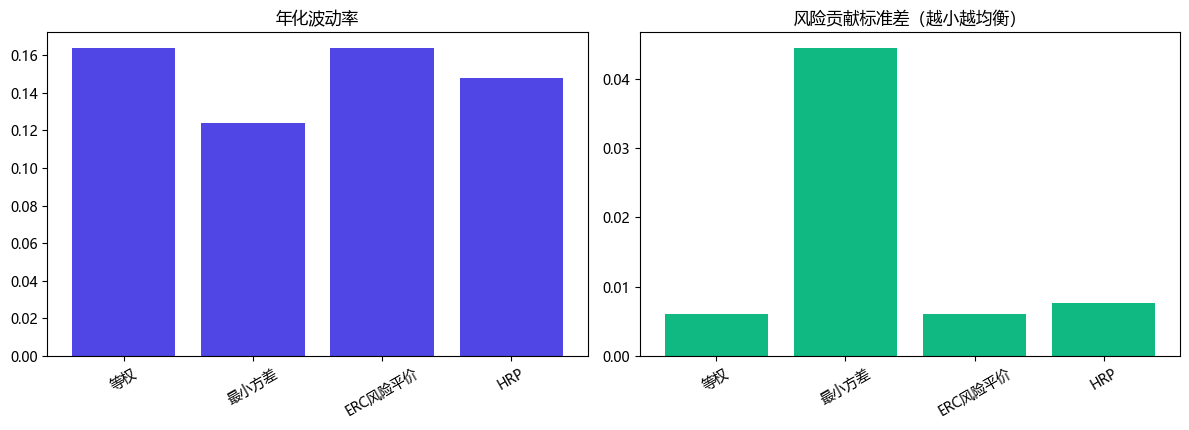

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
names = list(models.keys())
vols = [np.sqrt(wv @ S.values @ wv)*np.sqrt(242) for wv in models.values()]
rcstds = [rp.risk_contributions(wv, S).std() for wv in models.values()]
axes[0].bar(names, vols, color='#4f46e5'); axes[0].set_title('年化波动率')
axes[1].bar(names, rcstds, color='#10b981'); axes[1].set_title('风险贡献标准差（越小越均衡）')
for ax in axes: ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

## 七、结论与适用条件

- **等权**最简单，但风险被高波动资产主导，风险贡献不均；
- **ERC 风险平价**使各资产风险贡献相等，低波动资产获得更高权重，需数值优化、要求协方差良态；
- **HRP** 基于层次聚类与递归二分，不要求协方差可逆，在高维/病态、强相关下最稳健，分散度好；
- **最小方差**波动最低但集中度高、可能角点化；
- 桥水全天候是风险平价的多资产代表；HRP 更适合高维股票池与稳健配置。

## 八、面试要点

- **风险平价与等权的区别？** 等权平均资金，风险平价平均风险贡献，低波动资产配更多；
- **风险贡献怎么算？** $RC_i=w_i(\Sigma w)_i/\sigma_p^2$，所有 RC 之和为 1；
- **ERC 怎么求解？** 最小化风险贡献离散度，约束和为 1、非负；
- **HRP 三步及优势？** 距离聚类、准对角化、递归二分；不依赖协方差求逆，高维稳健；
- **风险平价的局限？** 假设低波动资产持续低风险，可能加杠杆，对协方差估计仍敏感。

## 动手练习
1. 计算等权组合各资产风险贡献，找出主导风险来源；
2. 求解 ERC 并验证风险贡献近似相等；
3. 绘制 HRP 聚类树，对比四种模型的年化波动与风险贡献标准差。

---
M4 组合风险（上）B6 全部完成，下一批 B7 进入组合风险（下）。